# Final Project: Hotel Booking Data Analysis

## 1. Introduction

For this report, we will be using the Hotels Bookings dataset. The data covers bookings made at two hotels, one City Hotel and one Resort Hotel, with planned arrival dates from July 2015 to August 2017. It contains 1,000 bookings: 642 at the City Hotel and 358 at the Resort Hotel.

Each row in this dataset is a single hotel booking. It records the hotel type (either City Hotel or Resort Hotel), when the guest planned to arrive, how long they planned to stay, the guest’s details (such as the number of adults, children and babies, country, and whether they are a repeat guest), the booking channel, the average daily rate (ADR) charged, and whether the booking was eventually cancelled (is_canceled).

The purpose of this report is to understand what drives booking cancellations and how guest behaviour and pricing differ between the two hotel types. These type of reports can help hotels with revenue forecasting and help answer these research questions:

### 1. Do cancellation rates differ between the City Hotel and the Resort Hotel?

### 2. How do length of stay and average daily rate differ between the City Hotel and the Resort Hotel?

### 3. Is the number of special requests associated with cancellation?

## 2. Load and inspect the data

In [1]:
import pandas as pd

pd.set_option("display.max_columns", None)

# Load
hotel_bookings = pd.read_csv("hotel_bookings_final_project.csv")

# Preview 
hotel_bookings.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,country,market_segment,deposit_type,customer_type,average_daily_rate,is_repeated_guest,booking_changes,required_car_parking_spaces,total_of_special_requests
0,City Hotel,1,1,2015,September,30,0,2,1,0,0,PRT,Offline TA/TO,Non Refund,Transient,98.10,1,0,0,0
1,Resort Hotel,1,19,2016,March,19,2,4,2,0,0,PRT,Online TA,No Deposit,Transient,70.17,0,0,0,1
2,Resort Hotel,0,9,2017,August,1,0,4,2,0,0,ESP,Online TA,No Deposit,Transient,193.40,0,0,0,1
3,Resort Hotel,0,110,2016,November,11,0,1,2,0,0,BRA,Online TA,No Deposit,Transient,36.24,0,2,1,0
4,City Hotel,0,329,2017,July,27,0,2,2,0,0,GBR,Online TA,No Deposit,Transient,89.10,0,0,0,1


In [3]:
# Shape
print("Rows:", hotel_bookings.shape[0],
      "| Columns:", hotel_bookings.shape[1])

print("\nColumn names and data types:")
hotel_bookings.info()
hotel_bookings.dtypes

Rows: 1000 | Columns: 20

Column names and data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   hotel                        1000 non-null   object 
 1   is_canceled                  1000 non-null   int64  
 2   lead_time                    1000 non-null   int64  
 3   arrival_date_year            1000 non-null   int64  
 4   arrival_date_month           1000 non-null   object 
 5   arrival_date_day_of_month    1000 non-null   int64  
 6   stays_in_weekend_nights      1000 non-null   int64  
 7   stays_in_week_nights         1000 non-null   int64  
 8   adults                       1000 non-null   int64  
 9   children                     1000 non-null   int64  
 10  babies                       1000 non-null   int64  
 11  country                      998 non-null    object 
 12  market_segment        

hotel                           object
is_canceled                      int64
lead_time                        int64
arrival_date_year                int64
arrival_date_month              object
arrival_date_day_of_month        int64
stays_in_weekend_nights          int64
stays_in_week_nights             int64
adults                           int64
children                         int64
babies                           int64
country                         object
market_segment                  object
deposit_type                    object
customer_type                   object
average_daily_rate             float64
is_repeated_guest                int64
booking_changes                  int64
required_car_parking_spaces      int64
total_of_special_requests        int64
dtype: object

In [4]:
hotel_bookings.describe().round(2)

,is_canceled,lead_time,arrival_date_year,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,average_daily_rate,is_repeated_guest,booking_changes,required_car_parking_spaces,total_of_special_requests
count,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00
mean,0.37,105.06,2016.13,16.13,0.92,2.52,1.86,0.11,0.01,101.21,0.03,0.24,0.06,0.59
std,0.48,106.45,0.70,8.96,0.95,1.80,0.53,0.40,0.09,45.72,0.18,0.67,0.24,0.80
min,0.00,0.00,2015.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.00,19.00,2016.00,8.00,0.00,1.00,2.00,0.00,0.00,68.57,0.00,0.00,0.00,0.00
50%,0.00,69.50,2016.00,16.00,1.00,2.00,2.00,0.00,0.00,94.50,0.00,0.00,0.00,0.00
75%,1.00,157.00,2017.00,24.00,2.00,3.00,2.00,0.00,0.00,125.00,0.00,0.00,0.00,1.00
max,1.00,542.00,2017.00,31.00,8.00,20.00,6.00,3.00,1.00,304.00,1.00,7.00,1.00,5.00


In [5]:
# Duplicates and missing values
print("Duplicate rows:", hotel_bookings.duplicated().sum())


print("\nMissing values:")
missing = hotel_bookings.isna().sum()
print(missing[missing > 0])


Duplicate rows: 26

Missing values:
country    2
dtype: int64


In [6]:
# Useful category counts
print("Hotel type:")
print(hotel_bookings["hotel"].value_counts(dropna=False))

print("\nCancelled (1 = cancelled):")
print(hotel_bookings["is_canceled"].value_counts(dropna=False))

print("\nSpecial requests:")
print(hotel_bookings["total_of_special_requests"].value_counts().sort_index())

print("\nMarket segment:")
print(hotel_bookings["market_segment"].value_counts(dropna=False))

print("\nDeposit type:")
print(hotel_bookings["deposit_type"].value_counts(dropna=False))

Hotel type:
hotel
City Hotel      642
Resort Hotel    358
Name: count, dtype: int64

Cancelled (1 = cancelled):
is_canceled
0    634
1    366
Name: count, dtype: int64

Special requests:
total_of_special_requests
0    574
1    286
2    117
3     20
4      2
5      1
Name: count, dtype: int64

Market segment:
market_segment
Online TA        481
Offline TA/TO    209
Groups           163
Direct           100
Corporate         41
Complementary      6
Name: count, dtype: int64

Deposit type:
deposit_type
No Deposit    881
Non Refund    116
Refundable      3
Name: count, dtype: int64


In [7]:
# Numerical summary statistics
numeric_cols = [
    "lead_time",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "average_daily_rate",
    "total_of_special_requests"
]

hotel_bookings[numeric_cols].describe().round(2)

,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,average_daily_rate,total_of_special_requests
count,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00
mean,105.06,0.92,2.52,1.86,0.11,0.01,101.21,0.59
std,106.45,0.95,1.80,0.53,0.40,0.09,45.72,0.80
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,19.00,0.00,1.00,2.00,0.00,0.00,68.57,0.00
50%,69.50,1.00,2.00,2.00,0.00,0.00,94.50,0.00
75%,157.00,2.00,3.00,2.00,0.00,0.00,125.00,1.00
max,542.00,8.00,20.00,6.00,3.00,1.00,304.00,5.00


## 3. Asses and Clean the Data

In [8]:
# Missing values
hotel_bookings.loc[
    hotel_bookings["country"].isna(),
    ["hotel", "country", "market_segment"]
]

,hotel,country,market_segment
122,Resort Hotel,NaN,Corporate
648,Resort Hotel,NaN,Corporate


In [9]:
# Exact duplicates
duplicate_rows = hotel_bookings[hotel_bookings.duplicated()]

print("Duplicate rows:", len(duplicate_rows))
print("\nBy hotel:")
print(duplicate_rows["hotel"].value_counts())
print("\nBy market segment:")
print(duplicate_rows["market_segment"].value_counts())
print("\nCancelled share among duplicates:", round(duplicate_rows["is_canceled"].mean(), 2))

Duplicate rows: 26

By hotel:
hotel
City Hotel      24
Resort Hotel     2
Name: count, dtype: int64

By market segment:
market_segment
Groups           16
Offline TA/TO    10
Name: count, dtype: int64

Cancelled share among duplicates: 0.77


In [10]:
# Invalid date combinations
month_number = pd.to_datetime(
    hotel_bookings["arrival_date_month"],
    format="%B",
    errors="coerce"
).dt.month

arrival_date_raw = pd.to_datetime(
    {
        "year": hotel_bookings["arrival_date_year"],
        "month": month_number,
        "day": hotel_bookings["arrival_date_day_of_month"]
    },
    errors="coerce"
)

print("Invalid month names:", month_number.isna().sum())
print("Invalid year-month-day combinations:", arrival_date_raw.isna().sum())
print("Earliest arrival:", arrival_date_raw.min().date())
print("Latest arrival:", arrival_date_raw.max().date())

Invalid month names: 0
Invalid year-month-day combinations: 0
Earliest arrival: 2015-07-01
Latest arrival: 2017-08-31


In [11]:
# Impossible negative values
numeric_raw = hotel_bookings.select_dtypes(include="number")

print("Negative values in numeric columns:", (numeric_raw < 0).sum().sum())

Negative values in numeric columns: 0


In [12]:
# Bookings with zero total guests
total_guests_raw = hotel_bookings["adults"] + hotel_bookings["children"] + hotel_bookings["babies"]

print("Bookings with zero total guests:", (total_guests_raw == 0).sum())

hotel_bookings.loc[
    total_guests_raw == 0,
    ["hotel", "adults", "children", "babies", "stays_in_week_nights", "average_daily_rate", "is_canceled"]
]

Bookings with zero total guests: 3


,hotel,adults,children,babies,stays_in_week_nights,average_daily_rate,is_canceled
201,City Hotel,0,0,0,0,0.0,0
774,City Hotel,0,0,0,0,0.0,0
993,City Hotel,0,0,0,0,0.0,0


In [13]:
# Bookings with zero total nights
total_nights_raw = hotel_bookings["stays_in_weekend_nights"] + hotel_bookings["stays_in_week_nights"]

print("Bookings with zero total nights:", (total_nights_raw == 0).sum())
print("Of these, also zero guests:", ((total_nights_raw == 0) & (total_guests_raw == 0)).sum())

hotel_bookings.loc[
    total_nights_raw == 0,
    ["hotel", "market_segment", "adults", "average_daily_rate", "is_canceled"]
]

Bookings with zero total nights: 5
Of these, also zero guests: 3


,hotel,market_segment,adults,average_daily_rate,is_canceled
201,City Hotel,Online TA,0,0.0,0
455,Resort Hotel,Groups,1,0.0,0
461,City Hotel,Offline TA/TO,1,0.0,0
774,City Hotel,Offline TA/TO,0,0.0,0
993,City Hotel,Online TA,0,0.0,0


In [14]:
# Unusual values in lead_time
print(hotel_bookings["lead_time"].describe().round(1))

long_lead = hotel_bookings[hotel_bookings["lead_time"] > 365]

print("\nBookings made more than 365 days ahead:", len(long_lead))
print(long_lead["market_segment"].value_counts())
print("\nSame-day bookings (lead time = 0):", (hotel_bookings["lead_time"] == 0).sum())

count    1000.0
mean      105.1
std       106.4
min         0.0
25%        19.0
50%        69.5
75%       157.0
max       542.0
Name: lead_time, dtype: float64

Bookings made more than 365 days ahead: 28
market_segment
Groups           16
Offline TA/TO    12
Name: count, dtype: int64

Same-day bookings (lead time = 0): 44


In [15]:
# Unusual values in average_daily_rate
adr = hotel_bookings["average_daily_rate"]

print(adr.describe().round(1))

print("\nADR of 0 or less:", (adr <= 0).sum())
print(hotel_bookings.loc[adr <= 0, "market_segment"].value_counts())

# Upper fence = Q3 + 1.5 * IQR
q1, q3 = adr.quantile([0.25, 0.75])
upper_fence = q3 + 1.5 * (q3 - q1)
high_adr = hotel_bookings[adr > upper_fence]

print("\nUpper fence:", round(upper_fence, 1))
print("Bookings above the fence:", len(high_adr))
print(high_adr["hotel"].value_counts())
print(high_adr["arrival_date_month"].value_counts().head(3))

count    1000.0
mean      101.2
std        45.7
min         0.0
25%        68.6
50%        94.5
75%       125.0
max       304.0
Name: average_daily_rate, dtype: float64

ADR of 0 or less: 15
market_segment
Complementary    6
Online TA        3
Offline TA/TO    3
Groups           2
Direct           1
Name: count, dtype: int64

Upper fence: 209.6
Bookings above the fence: 25
hotel
Resort Hotel    18
City Hotel       7
Name: count, dtype: int64
arrival_date_month
August    12
May        3
June       3
Name: count, dtype: int64


### Cleaning Log

| Issue checked | Evidence | Decision | Reason |
|---|---|---|---|
| Missing values | Only `country` has missing values: 2 rows, both Resort Hotel / Corporate | Keep the rows and fill with `"Unknown"` | We didn't use Country in any research question, so deleting valid bookings would lose information for nothing |
| Exact duplicates | 26 duplicate rows (24 City Hotel, 2 Resort Hotel). All are Groups or Offline TA/TO bookings, and 20 of the 26 were cancelled | Remove the duplicates and keep the first copy | The rows match in all 20 columns, so they are treated as repeated records. |
| Invalid date combinations | 0 invalid month names and 0 impossible dates. Arrivals run from 2015-07-01 to 2017-08-31 | Keep all rows and create an `arrival_date` column | Every year, month and day combination converts to a real date |
| Impossible negative values | 0 negative values in any numeric column | No action | Nothing to fix |
| Zero total guests | 3 bookings with 0 adults, 0 children and 0 babies. All are City Hotel, none cancelled, and all also have 0 nights and an ADR of 0 | Remove these rows | A booking with no guests, no nights and no price does not count as a real stay |
| Zero total nights | 5 bookings (3 of them are the zero-guest rows above); the other 2 are also not cancelled and have an ADR of 0 | Set `total_nights` to missing and keep the rows | A stay cannot last zero nights, so these cannot be used for Question 2. The rows are still usable for cancellation questions |
| Unusual `lead_time` | Median 69.5 days, maximum 542. 28 bookings were made more than 365 days ahead, all Groups or Offline TA/TO. 44 are same-day bookings (0 days) | Keep all values | Long lead times are plausible for group and agency bookings, and same-day bookings are normal. |
| Unusual `average_daily_rate` | 15 bookings have an ADR of 0 or less (6 are Complementary). Maximum is 304. 25 bookings are above the upper fence of about 209.6, mostly at the Resort Hotel in August | Set ADR of 0 or less to missing. Keep high ADR values | A rate of 0 is not a nightly price, so these rows are left out of Question 2 only. High rates fit peak-season pricing, so they are kept, and the median is reported next to the mean |

In [16]:
# New copy
hotels = hotel_bookings.copy()
rows_before = len(hotels)

# Remove exact duplicates (rows identical in every column)
hotels = hotels.drop_duplicates().copy()
rows_after_duplicates = len(hotels)

# Country is not used in the research questions, so we put the unknown label
hotels["country"] = hotels["country"].fillna("Unknown")

# Build a real arrival date from the year, month name and day columns
month_number = pd.to_datetime(hotels["arrival_date_month"], format="%B").dt.month
hotels["arrival_date"] = pd.to_datetime(
    {
        "year": hotels["arrival_date_year"],
        "month": month_number,
        "day": hotels["arrival_date_day_of_month"]
    }
)

# Remove bookings with no guests (not real stays)
hotels["total_guests"] = hotels["adults"] + hotels["children"] + hotels["babies"]
hotels = hotels[hotels["total_guests"] > 0].copy()

# A stay cannot last zero nights, so those become missing instead of removing the booking
hotels["total_nights"] = hotels["stays_in_weekend_nights"] + hotels["stays_in_week_nights"]
hotels["total_nights"] = hotels["total_nights"].where(hotels["total_nights"] > 0)

# An ADR of 0 or less is not a real nightly price, so it becomes missing
hotels["average_daily_rate"] = hotels["average_daily_rate"].where(hotels["average_daily_rate"] > 0)

print("Rows before cleaning:", rows_before)
print("Rows after removing duplicates:", rows_after_duplicates)
print("Rows after cleaning:", len(hotels))

Rows before cleaning: 1000
Rows after removing duplicates: 974
Rows after cleaning: 971


In [17]:
print("Original DataFrame unchanged:", hotel_bookings.shape)
print("Cleaned DataFrame:", hotels.shape)

print("\nMissing values created by cleaning:")
print(hotels[["total_nights", "average_daily_rate"]].isna().sum())

hotels[["hotel", "arrival_date", "total_guests", "total_nights", "average_daily_rate"]].head()

Original DataFrame unchanged: (1000, 20)
Cleaned DataFrame: (971, 23)

Missing values created by cleaning:
total_nights           2
average_daily_rate    12
dtype: int64


,hotel,arrival_date,total_guests,total_nights,average_daily_rate
0,City Hotel,2015-09-30,1,2.0,98.10
1,Resort Hotel,2016-03-19,2,6.0,70.17
2,Resort Hotel,2017-08-01,2,4.0,193.40
3,Resort Hotel,2016-11-11,2,1.0,36.24
4,City Hotel,2017-07-27,2,2.0,89.10


## 4. Transform and Enrich the data

In [18]:
# Estimated booking value = average daily rate × total nights

hotels["estimated_booking_value"] = (
    hotels["average_daily_rate"] * hotels["total_nights"]
)

# Display the four required derived variables
hotels[
    [
        "arrival_date",
        "total_nights",
        "total_guests",
        "estimated_booking_value"
    ]
].head()

,arrival_date,total_nights,total_guests,estimated_booking_value
0,2015-09-30,2.0,1,196.20
1,2016-03-19,6.0,2,421.02
2,2017-08-01,4.0,2,773.60
3,2016-11-11,1.0,2,36.24
4,2017-07-27,2.0,2,178.20


The arrival_date, total_nights and total_guests were created during data cleaning. We calculated estimated_booking_value by muliplying the average daily rate by the total number of nights. 
This is an estimated accomodation value, not the actual revenue. Cancelled bookings may not generate this amount. The estimated value is missing where the cleaned daily rate or total nights are missing. 


In [19]:
# Checking the data types and missing values of the derived variables

derived_columns = [
    "arrival_date",
    "total_nights",
    "total_guests",
    "estimated_booking_value"
]

display(hotels[derived_columns].dtypes)
display(hotels[derived_columns].isna().sum())

# Inspecting the calculation alongside its inputs

display(
    hotels[
        [
            "average_daily_rate",
            "total_nights",
            "estimated_booking_value"
        ]
    ].head()
)

arrival_date               datetime64[ns]
total_nights                      float64
total_guests                        int64
estimated_booking_value           float64
dtype: object

arrival_date                0
total_nights                2
total_guests                0
estimated_booking_value    12
dtype: int64

,average_daily_rate,total_nights,estimated_booking_value
0,98.10,2.0,196.20
1,70.17,6.0,421.02
2,193.40,4.0,773.60
3,36.24,1.0,36.24
4,89.10,2.0,178.20


## 5.Analyze individual variables

### 5.1 Hotel type


We are examining the number and percentage of bookings for each hotel type in the cleaned dataset. Percentages are calculated out of bookings
with a recorded hotel type.

In [21]:
# Counting bookings with a recorded hotel type
hotel_n = hotels["hotel"].notna().sum()

# Calculating counts and percentages
hotel_counts = hotels["hotel"].value_counts()

hotel_summary = hotel_counts.rename("Count").to_frame()
hotel_summary["Percentage (%)"] = (
    hotel_summary["Count"] / hotel_n * 100
).round(2)

print(f"Valid sample size (n): {hotel_n}")
display(hotel_summary)

Valid sample size (n): 971


,Count,Percentage (%)
hotel,,
City Hotel,615,63.34
Resort Hotel,356,36.66


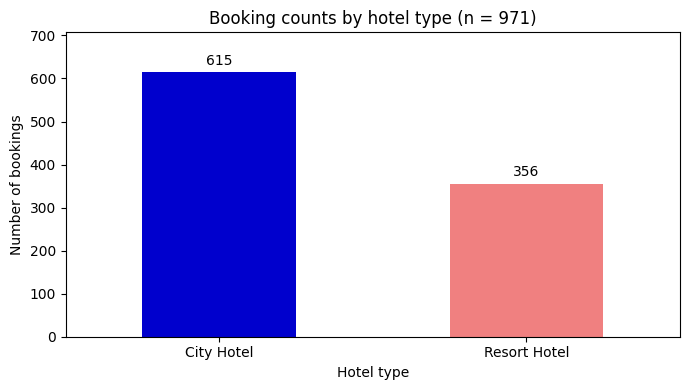

In [25]:
import matplotlib.pyplot as plt

ax = hotel_summary["Count"].plot(
    kind="bar",
    figsize=(7, 4),
    color=["mediumblue", "lightcoral"],
    rot=0
)

ax.set_title(f"Booking counts by hotel type (n = {hotel_n})")
ax.set_xlabel("Hotel type")
ax.set_ylabel("Number of bookings")

# Show the count above each bar
ax.bar_label(ax.containers[0], padding=3)
ax.set_ylim(0, hotel_summary["Count"].max() * 1.15)

plt.tight_layout()
plt.show()

Of the 971 cleaned bookings with a recorded hotel type, 615 (63.34%) were at City Hotel and 356 (36.66%) were at Resort Hotel. City Hotel therefore accounts for almost two-thirds of the bookings in the cleaned sample.

These percentages describe the composition of the supplied sample, including both cancelled and not-cancelled bookings. They do not establish either hotel’s total demand or occupancy. Because the hotel sample sizes differ, cancellation comparisons in section 6 use percentages within each hotel rather than cancellation counts alone.

### 5.2 Cancellation status


We are examining the number and percentage of cancelled and not-cancelled bookings in the cleaned dataset. Percentages use bookings with a recorded cancellation status as the denominator.

In [26]:
# Giving the categories readable labels
cancellation_status = hotels["is_canceled"].map(
    {0: "Not cancelled", 1: "Cancelled"}
)

cancellation_n = cancellation_status.notna().sum()

cancellation_counts = cancellation_status.value_counts()

cancellation_summary = cancellation_counts.rename("Count").to_frame()
cancellation_summary["Percentage (%)"] = (
    cancellation_summary["Count"] / cancellation_n * 100
).round(2)

print(f"Valid sample size (n): {cancellation_n}")
display(cancellation_summary)

Valid sample size (n): 971


,Count,Percentage (%)
is_canceled,,
Not cancelled,625,64.37
Cancelled,346,35.63


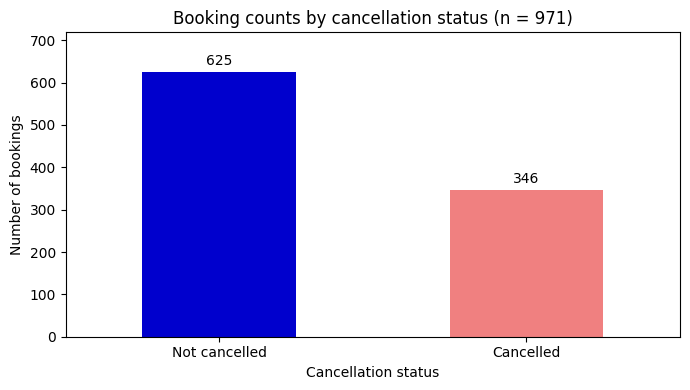

In [28]:
ax = cancellation_summary["Count"].plot(
    kind="bar",
    figsize=(7, 4),
    color=["mediumblue", "lightcoral"],
    rot=0
)

ax.set_title(
    f"Booking counts by cancellation status (n = {cancellation_n})"
)
ax.set_xlabel("Cancellation status")
ax.set_ylabel("Number of bookings")

ax.bar_label(ax.containers[0], padding=3)
ax.set_ylim(0, cancellation_summary["Count"].max() * 1.15)

plt.tight_layout()
plt.show()

Of the 971 cleaned bookings with a valid cancellation status, 346 (35.63%) were cancelled and 625 (64.37%) were not cancelled. Percentages use all 971 bookings as the denominator.
The bar chart shows that bookings recorded as not cancelled were more common, although cancellations still accounted for more than one-third of the sample. These results describe the overall cancellation pattern in the cleaned sample. Section 6 examines whether cancellation rates differ between hotel types and according to the number of special requests.

### 5.3 Total nights

Total nights is the sum of weekend and weekday nights in a booking. We will examine booked stay lengths using records with a valid total. Cancelled bookings are included, so this describes planned stays, but not necessarily completed stays.

In [29]:
# Using bookings with a valid total number of nights
stay_lengths = hotels["total_nights"].dropna()

stay_summary = stay_lengths.agg(
    ["count", "mean", "median", "std", "min", "max"]
).rename(
    {
        "count": "Valid n",
        "mean": "Mean",
        "median": "Median",
        "std": "Standard deviation",
        "min": "Minimum",
        "max": "Maximum"
    }
)

display(stay_summary.round(2).to_frame("Total nights"))

print(
    "Bookings excluded due to missing total nights:",
    hotels["total_nights"].isna().sum()
)

,Total nights
Valid n,969.00
Mean,3.49
Median,3.00
Standard deviation,2.40
Minimum,1.00
Maximum,28.00


Bookings excluded due to missing total nights: 2


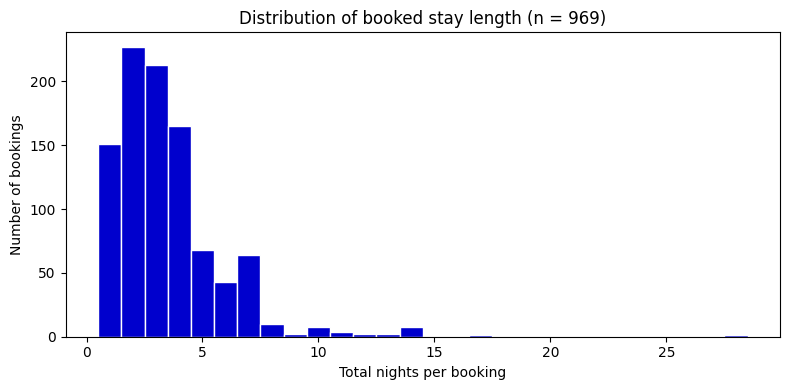

In [ ]:
# Center each bin on a whole number of nights
night_bins = [
    night - 0.5
    for night in range(
        int(stay_lengths.min()),
        int(stay_lengths.max()) + 2
    )
]

fig, ax = plt.subplots(figsize=(8, 4))

ax.hist(
    stay_lengths,
    bins=night_bins,
    color="mediumblue",
    edgecolor="white"
)

ax.set_title(
    f"Distribution of booked stay length (n = {len(stay_lengths)})"
)
ax.set_xlabel("Total nights per booking")
ax.set_ylabel("Number of bookings")

plt.tight_layout()
plt.show()

Among the 969 bookings with a valid stay length, the mean was 3.49 nights and the median was 3 nights. Stay lengths ranged from 1 to 28 nights, with a standard deviation of 2.40 nights.

The histogram shows that short stays were most common, with two nights being the most frequent stay length. The distribution is right-skewed: a small number of longer stays pull the mean above the median.

Two bookings were excluded because their zero total nights were set to missing during cleaning. Cancelled bookings are included, so these results describe planned stay lengths rather than confirmed completed stays.

### 5.4 Average daily rate

We will examine the recorded average daily rate per booking. Only valid positive rates are included, because zero rates were set to missing during cleaning. Cancelled bookings are included, so these rates do not represent actual revenue.

In [31]:
# Using bookings with a valid recorded daily rate
daily_rates = hotels["average_daily_rate"].dropna()

rate_summary = daily_rates.agg(
    ["count", "mean", "median", "std", "min", "max"]
).rename(
    {
        "count": "Valid n",
        "mean": "Average (mean)",
        "median": "Median",
        "std": "Standard deviation",
        "min": "Minimum",
        "max": "Maximum"
    }
)

display(rate_summary.round(2).to_frame("Average daily rate"))

print(
    "Bookings excluded due to missing daily rate:",
    hotels["average_daily_rate"].isna().sum()
)

,Average daily rate
Valid n,959.00
Average (mean),103.03
Median,95.00
Standard deviation,44.70
Minimum,6.00
Maximum,304.00


Bookings excluded due to missing daily rate: 12


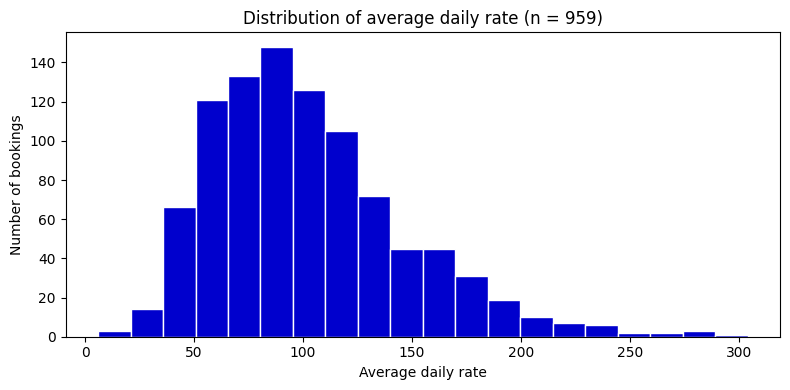

In [32]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.hist(
    daily_rates,
    bins=20,
    color="mediumblue",
    edgecolor="white"
)

ax.set_title(
    f"Distribution of average daily rate (n = {len(daily_rates)})"
)
ax.set_xlabel("Average daily rate")
ax.set_ylabel("Number of bookings")

plt.tight_layout()
plt.show()

Among the 959 bookings with a valid positive average daily rate, the mean was 103.03 and the median was 95.00. Rates ranged from 6.00 to 304.00, with a standard deviation of 44.70.

The histogram shows a right-skewed distribution, with rates concentrated at lower and middle values and fewer bookings at higher rates. These higher values pull the mean above the median, so reporting both measures gives a clearer picture of typical prices.

Twelve bookings were excluded because their zero daily rates were set to missing during cleaning. Zero rates may represent complimentary or other non-chargeable bookings, so these statistics describe positive recorded rates rather than all booking rates. Cancelled bookings are included, and the recorded rates do not represent actual revenue received.

## 6. Analyze relationships between variables

### 6.1 Cancellation status by hotel type


We will compare cancellation patterns between City Hotel and Resort Hotel using a crosstab of booking counts and percentages.

Percentages are calculated within each hotel: the denominator is the number of bookings with a valid cancellation status for that hotel. Each percentage row therefore totals 100%.

In [34]:
# Creating readable cancellation labels
cancellation_labels = hotels["is_canceled"].map(
    {0: "Not cancelled", 1: "Cancelled"}
)

# Booking counts for each hotel and cancellation category
hotel_cancellation_counts = pd.crosstab(
    hotels["hotel"],
    cancellation_labels
).reindex(columns=["Not cancelled", "Cancelled"], fill_value=0)

hotel_cancellation_counts.columns.name = "Cancellation status"

# Calculating percentages within each hotel
hotel_cancellation_percentages = (
    hotel_cancellation_counts.div(
        hotel_cancellation_counts.sum(axis=1),
        axis=0
    ) * 100
)

print("Booking counts:")
display(hotel_cancellation_counts)

print("Percentages within each hotel (%):")
display(hotel_cancellation_percentages.round(2))

print("Valid sample size (n) for each hotel:")
display(
    hotel_cancellation_counts.sum(axis=1).to_frame("Valid n")
)

Booking counts:


Cancellation status,Not cancelled,Cancelled
hotel,,
City Hotel,354,261
Resort Hotel,271,85


Percentages within each hotel (%):


Cancellation status,Not cancelled,Cancelled
hotel,,
City Hotel,57.56,42.44
Resort Hotel,76.12,23.88


Valid sample size (n) for each hotel:


,Valid n
hotel,
City Hotel,615
Resort Hotel,356


City Hotel had 261 cancellations out of 615 bookings (42.44%), compared with 85 cancellations out of 356 bookings (23.88%) at Resort Hotel. The cancellation rate was therefore 18.56 percentage points higher at City Hotel.

Percentages use the valid bookings within each hotel as the denominator, allowing comparison despite the different sample sizes. This answers research question 1: cancellation rates differed between the hotels in the cleaned sample. However, the comparison does not establish that hotel type causes cancellation.

### 6.2 Booked stay length and average daily rate by hotel

We will compare planned stay lengths and positive recorded daily rates between the hotels. Missing values are excluded separately for each variable, so their valid sample sizes may differ. Cancelled bookings are included.

In [35]:
# Summarizing stay length and daily rate separately for each hotel
hotel_numeric_summary = hotels.groupby("hotel").agg(
    nights_valid_n=("total_nights", "count"),
    nights_mean=("total_nights", "mean"),
    nights_median=("total_nights", "median"),
    nights_std=("total_nights", "std"),
    rate_valid_n=("average_daily_rate", "count"),
    rate_mean=("average_daily_rate", "mean"),
    rate_median=("average_daily_rate", "median"),
    rate_std=("average_daily_rate", "std")
)

display(hotel_numeric_summary.round(2))

,nights_valid_n,nights_mean,nights_median,nights_std,rate_valid_n,rate_mean,rate_median,rate_std
hotel,,,,,,,,
City Hotel,614,3.05,3.0,1.74,608,107.83,101.25,37.27
Resort Hotel,355,4.24,4.0,3.10,351,94.73,78.60,54.33


Resort Hotel bookings had longer planned stays: an average of 4.24 nights and a median of 4 nights, compared with 3.05 nights and a median of 3 nights at City Hotel. Stay lengths also varied more at Resort Hotel.

City Hotel had higher positive recorded daily rates: an average of 107.83 and a median of 101.25, compared with 94.73 and 78.60 at Resort Hotel. Daily rates varied more at Resort Hotel, with a standard deviation of 54.33 compared with 37.27 at City Hotel.

These results answer research question 2: Resort Hotel had longer booked stays, while City Hotel had higher daily rates in the cleaned sample. Valid stay-length
counts were 614 and 355, and valid daily-rate counts were 608 and 351, for City and Resort Hotel respectively. The comparisons include cancelled bookings and do not account for differences in season or guest characteristics.

### 6.3 Special requests and cancellation status

We will investigate whether cancellation rates differ according to the number of special requests recorded for a booking.

Percentages are calculated within each special-request category. The denominator is the number of bookings with a valid cancellation status in that category.

In [36]:
# Counting cancellation outcomes for each number of special requests
requests_cancellation_counts = pd.crosstab(
    hotels["total_of_special_requests"],
    cancellation_labels
).reindex(columns=["Not cancelled", "Cancelled"], fill_value=0)

requests_cancellation_counts = (
    requests_cancellation_counts.sort_index()
)

requests_cancellation_counts.index.name = "Number of special requests"

# Calculating percentages within each request-count category
requests_cancellation_percentages = (
    requests_cancellation_counts.div(
        requests_cancellation_counts.sum(axis=1),
        axis=0
    ) * 100
)

print("Booking counts:")
display(requests_cancellation_counts)

print("Percentages within each special-request category (%):")
display(requests_cancellation_percentages.round(2))

print("Valid sample size (n) for each category:")
display(
    requests_cancellation_counts.sum(axis=1).to_frame("Valid n")
)

Booking counts:


is_canceled,Not cancelled,Cancelled
Number of special requests,,
0,288,261
1,223,59
2,93,24
3,18,2
4,2,0
5,1,0


Percentages within each special-request category (%):


is_canceled,Not cancelled,Cancelled
Number of special requests,,
0,52.46,47.54
1,79.08,20.92
2,79.49,20.51
3,90.00,10.00
4,100.00,0.00
5,100.00,0.00


Valid sample size (n) for each category:


,Valid n
Number of special requests,
0,549
1,282
2,117
3,20
4,2
5,1


Bookings with no special requests had a cancellation rate of 47.54% (261 of 549), compared with 20.92% for one request (59 of 282) and 20.51% for two requests (24 of 117). For three requests, the rate was 10.00% (2 of 20).

No cancellations were recorded for four or five requests, but these categories contained only two bookings and one booking respectively, so they provide very limited evidence.

These results answer research question 3: special requests were associated with lower cancellation rates in the cleaned sample. However, this does not establish that making requests prevents cancellation; other booking characteristics may help explain the pattern.

### 6.4 Monthly booking counts by hotel

We will group bookings by arrival year and month and by hotel type. Counts include both cancelled and not-cancelled bookings, so they represent scheduled arrivals rather than actual stays.

The sample covers July 2015 to August 2017. Monthly counts describe this sample and should not be treated as the hotels' complete booking volumes.

In [37]:
# Using bookings with a valid arrival date and hotel type
monthly_data = hotels.loc[
    hotels["arrival_date"].notna() & hotels["hotel"].notna(),
    ["arrival_date", "hotel"]
].copy()

# Keeping year and month together, so different years stay separate
monthly_data["arrival_month"] = (
    monthly_data["arrival_date"].dt.to_period("M")
)

# Counting bookings for each month and hotel
monthly_booking_counts = (
    monthly_data.groupby(["arrival_month", "hotel"])
    .size()
    .unstack("hotel", fill_value=0)
    .sort_index()
)

print(f"Valid sample size (n): {len(monthly_data)}")
display(monthly_booking_counts)

Valid sample size (n): 971


hotel,City Hotel,Resort Hotel
arrival_month,,
2015-07,13,14
2015-08,24,17
2015-09,17,12
2015-10,18,13
2015-11,10,11
2015-12,15,13
2016-01,11,4
2016-02,16,17
2016-03,24,13


Across the 971 bookings, monthly counts varied for both hotels. City Hotel had more bookings than Resort Hotel in most months.

Both hotels recorded their highest monthly counts in May 2017: 41 for City Hotel and 24 for Resort Hotel, giving a combined total of 65. The lowest combined count was in January 2016, with 15 bookings: 11 for City Hotel and 4 for Resort Hotel.

These counts describe scheduled arrivals in the supplied sample, including cancelled bookings. They do not represent actual stays or complete hotel demand. The limited time span and sample size do not establish a consistent seasonal pattern.

### 6.5 Lead time by cancellation status


Lead time is the number of days between making a booking and its planned arrival date. We will compare lead times for cancelled and not-cancelled bookings to explore whether booking further in advance is associated with cancellation.

In [38]:
# Summarizing lead time for each cancellation status
lead_time_summary = hotels.groupby("is_canceled").agg(
    valid_n=("lead_time", "count"),
    average_lead_time=("lead_time", "mean"),
    median_lead_time=("lead_time", "median"),
    standard_deviation=("lead_time", "std"),
    minimum=("lead_time", "min"),
    maximum=("lead_time", "max")
)

# Replacing 0 and 1 with readable labels
lead_time_summary.index = lead_time_summary.index.map(
    {0: "Not cancelled", 1: "Cancelled"}
)
lead_time_summary.index.name = "Cancellation status"

print("Lead time statistics (days):")
display(lead_time_summary.round(2))

Lead time statistics (days):


,valid_n,average_lead_time,median_lead_time,standard_deviation,minimum,maximum
Cancellation status,,,,,,
Not cancelled,625,82.75,48.0,92.44,0,542
Cancelled,346,139.87,113.0,115.55,0,538


Cancelled bookings were typically made further in advance. Their average lead time was 139.87 days, compared with 82.75 days for not-cancelled bookings—a difference of 57.12 days. The medians showed the same pattern: 113 days for cancelled bookings and 48 days for not-cancelled bookings.

Lead times also varied more among cancelled bookings, with a standard deviation of 115.55 days, compared with 92.44 days for not-cancelled bookings. The analysis included 346 cancelled and 625 not-cancelled bookings.

These results suggest an association between longer lead times and cancellation in the cleaned sample. They do not establish that booking earlier causes cancellation; other factors, such as hotel type or market segment, may contribute to the difference.